In [ ]:
!pip install openpyxl scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 6.0 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
from google.colab import drive
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.utils import shuffle
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical
from skopt import BayesSearchCV
from sklearn.calibration import CalibratedClassifierCV
import os

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


ID               0
aspect           0
curvature        0
dis_to_fault     0
dis_to_river     0
dis_to_thrust    0
dis_to_road      0
ndvi             0
nwdi             0
roughness        0
twi              0
slope            0
dtype: int64
      ID      aspect  curvature  dis_to_fault  dis_to_river  dis_to_thrust  \
1000   1   75.277310   0.000072      17334.42      885.8894       29352.02   
1001   1   65.364270   0.002496      17399.64      874.6428       29412.87   
1002   1  343.342200   0.000678      18516.59      664.0783       31009.29   
1003   1  335.776100   0.000514      18677.77      573.1492       31170.35   
1004   1  343.950600   0.002048      18530.63      684.1052       31029.05   
...   ..         ...        ...           ...           ...            ...   
1761   1  258.030000   0.000474      15766.56      692.6038       32661.72   
1762   1  232.606800   0.000528      15401.31      268.3282       32212.81   
1763   1  241.024100  -0.000610      15625.88      800.49

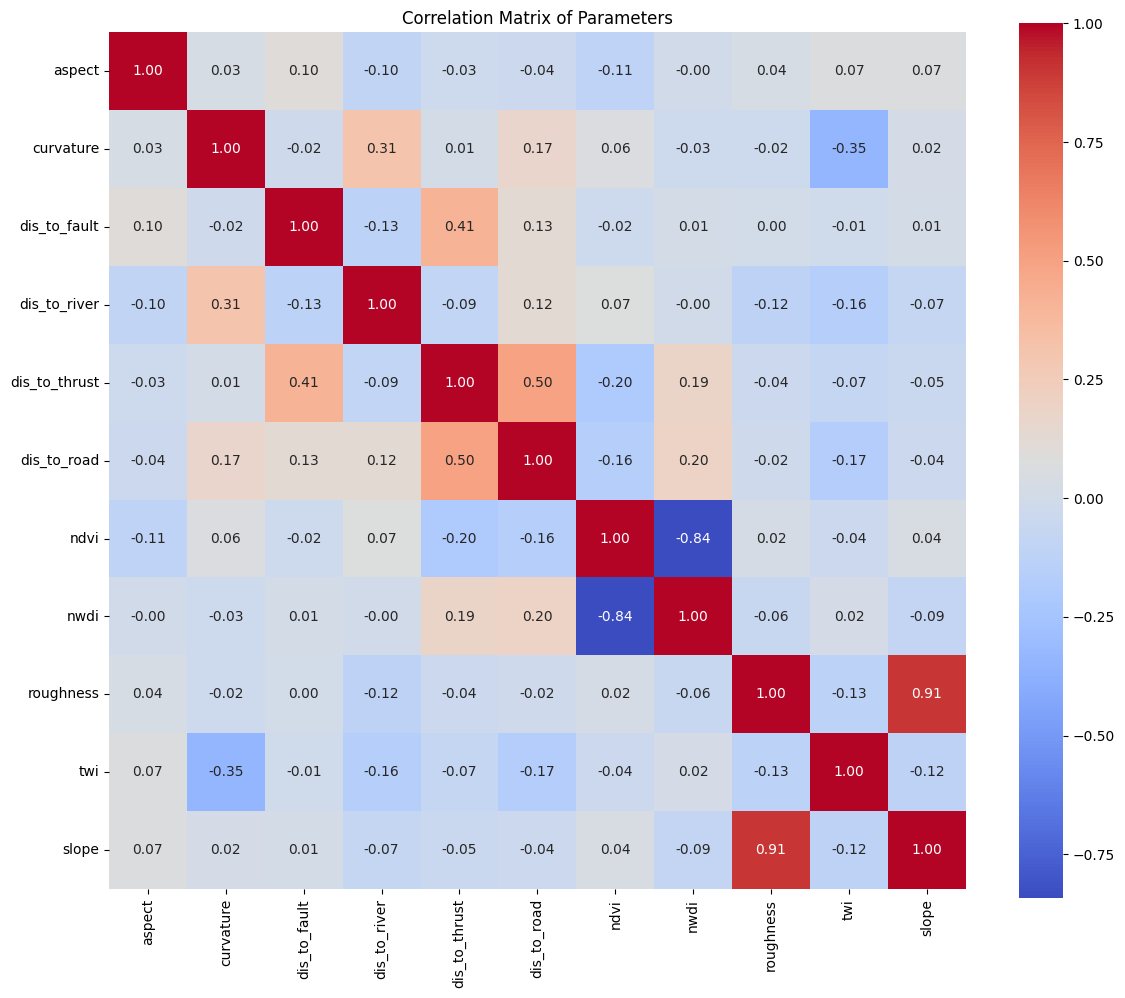

In [ ]:
excel_path = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/ls_non_ls_final.xlsx"
output_path = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/outputs/"
os.makedirs(output_path, exist_ok=True)

raster_files = [[
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/aspect_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/pcurve_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/fault_dis_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/river_dis_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/thrust_dis_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/road_dis_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/ndvi_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/ndwi_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/roughness_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/twi_coarse_25x25.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/25x25_rasters/slope_25x25.tif"
    ],
    [
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/aspect_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/pcurve_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/fault_dis_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/river_dis_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/thrust_dis_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/road_dis_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/ndvi_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/ndwi_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/roughness_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/twi_intermediate_15x15.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/15x15_rasters/slope_15x15.tif"
    ],
    [
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/aspect_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/pcurve_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/fault_dis_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/river_dis_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/thrust_dis_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/road_dis_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/ndvi_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/ndwi_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/roughness_3x3.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/twi_fine.tif",
    "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/3x3_rasters/slope_3x3.tif"
    ]]
raster_sets = {
    "25x25": raster_files[0],
    "15x15": raster_files[1],
    "3x3": raster_files[2],
}

with rasterio.open(raster_files[0][0]) as src:
    ref_profile = src.profile
# ==================== LOAD DATA ====================
df = pd.read_excel(excel_path)
df.columns = df.columns.str.strip()  # Strip whitespace
df = df.dropna()

# Show summary of missing values per column
print(df.isnull().sum())
print(df[df['ID'] == 1])
print(f"\n🔍 Total missing cells: {df.isnull().sum().sum()}")


# Separate label and features
y = df.iloc[:, 0].values  # ID column: 0 = non-LS, 1 = LS
X = df.iloc[:, 1:].copy()  # Remaining columns = features

# ==================== CORRELATION ANALYSIS ====================
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Correlation Matrix of Parameters")
plt.tight_layout()
plt.savefig(f"{output_path}/correlation_matrix.png")
plt.show()

# Optional: Remove highly correlated features (>0.9)
corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
# to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
# print("🔍 Dropping highly correlated features:", to_drop)
# X = X.drop(columns=to_drop)


In [ ]:
def predict_raster(model, raster_paths, ref_profile, scaler=None):
    features = []
    for path in raster_paths:
        with rasterio.open(path) as src:
            band = src.read(1).astype(np.float32)
            band[band == src.nodata] = np.nan
            features.append(band)
    full_stack = np.stack(features, axis=-1)
    mask_valid = ~np.isnan(full_stack).any(axis=-1)
    prediction = np.full(mask_valid.shape, np.nan, dtype=np.float32)
    input_data = full_stack[mask_valid]
    if scaler is not None:
        input_data = scaler.transform(input_data)
    prediction[mask_valid] = model.predict_proba(input_data)[:, 1]
    return prediction

[[ 3.49532000e+02 -1.46268000e-04  1.67281100e+04 ...  1.06000000e+02
   6.98533994e+00  2.79387000e+01]
 [ 2.65640000e+02 -5.13674000e-04  8.35945600e+03 ...  1.98000000e+02
   4.88395264e+00  4.31772500e+01]
 [ 2.21462100e+02 -4.23817000e-04  1.57734100e+04 ...  1.70000000e+02
   6.09197921e+00  3.50604800e+01]
 ...
 [ 1.76101600e+02  8.96994000e-04  1.40711500e+04 ...  1.83000000e+02
   4.57143749e+00  4.15968400e+01]
 [ 1.65856100e+02  1.11196600e-03  1.51040400e+04 ...  1.71000000e+02
   4.44646147e+00  3.71254600e+01]
 [ 1.03272300e+02 -9.67331000e-04  1.10522600e+04 ...  9.40000000e+01
   8.79983576e+00  1.75434600e+01]]
0.8755304101838756


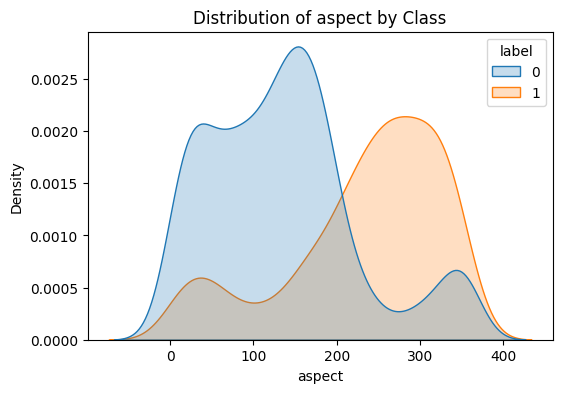

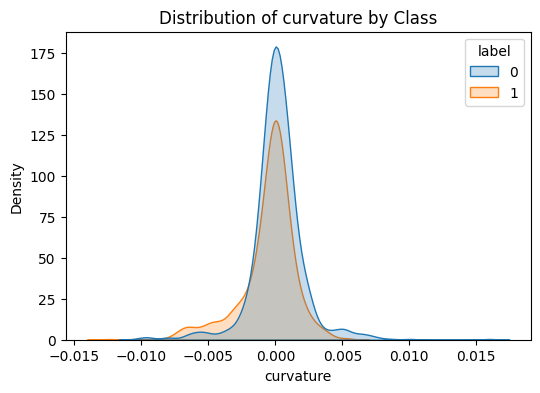

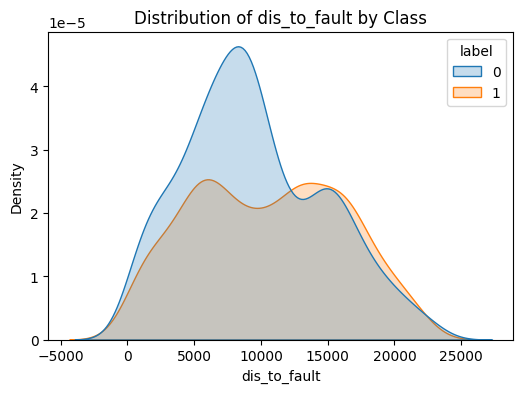

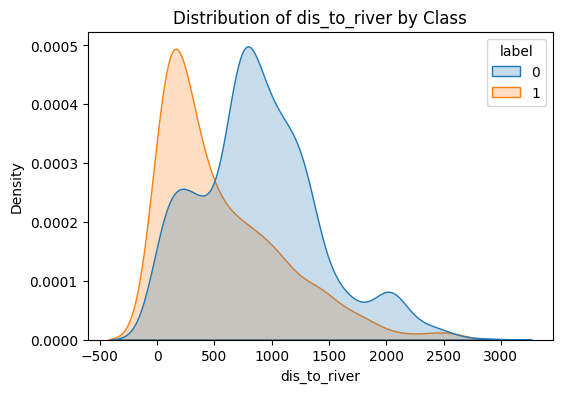

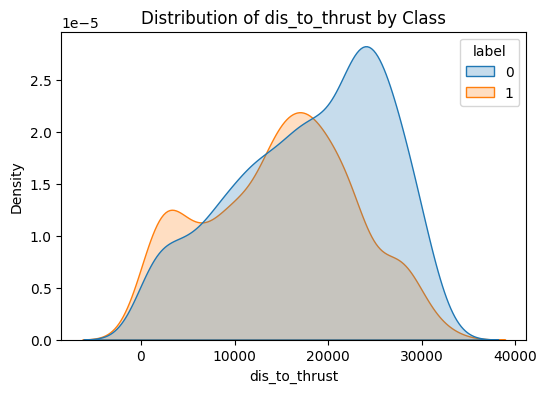

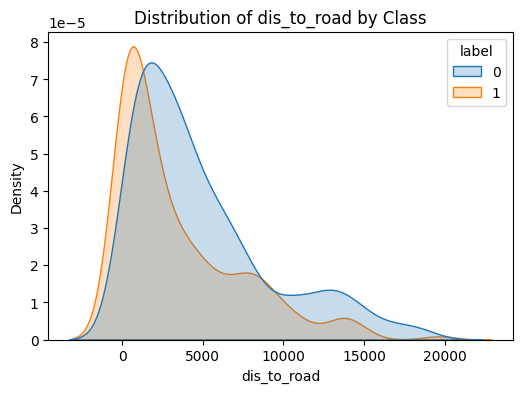

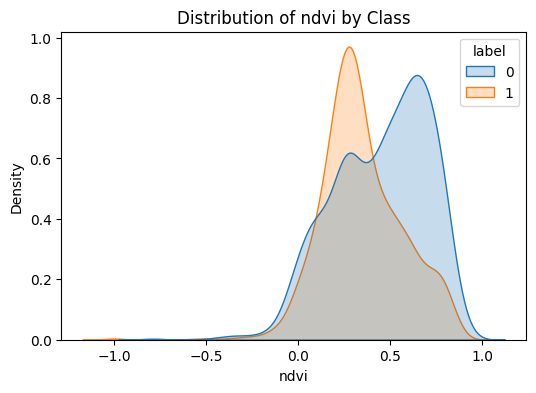

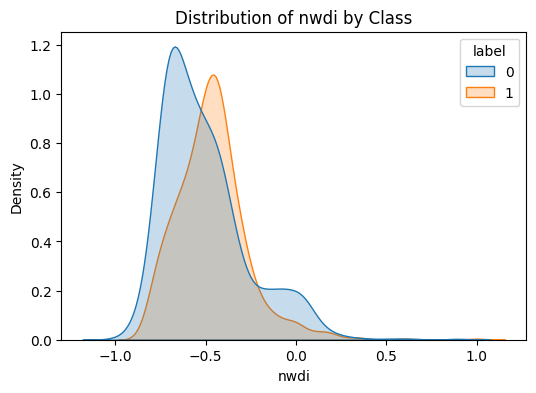

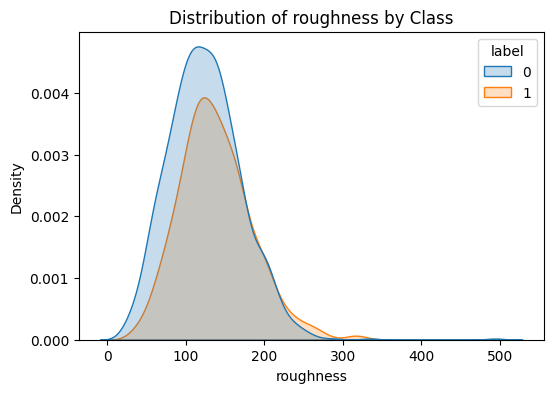

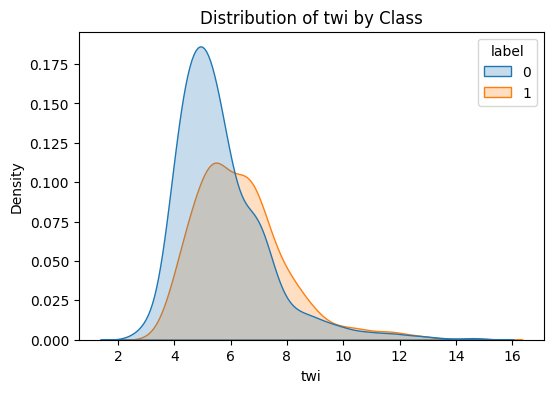

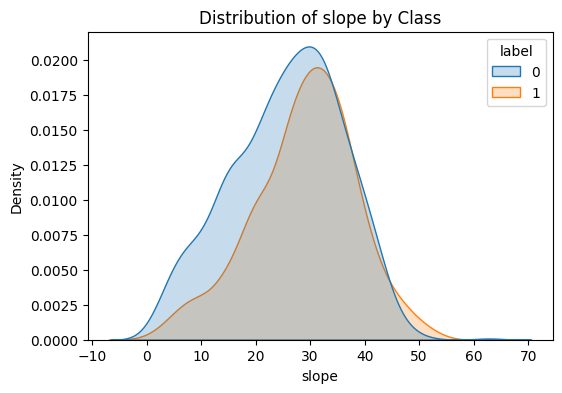

In [ ]:
# ✅ Split landslide and non-landslide points
X_ls = df[df['ID'] == 1].drop('ID', axis=1).values
y_ls = df[df['ID'] == 1]['ID'].values  # will be all 1s

X_non_ls = df[df['ID'] == 0].drop('ID', axis=1).values
y_non_ls = df[df['ID'] == 0]['ID'].values  # will be all 0s

# ✅ Perform train/test split separately for each class
X_ls_train, X_ls_test, y_ls_train, y_ls_test = train_test_split(
    X_ls, y_ls, test_size=0.4, random_state=42
)

X_non_train, X_non_test, y_non_train, y_non_test = train_test_split(
    X_non_ls, y_non_ls, test_size=0.4, random_state=42
)

# ✅ Combine train and test sets to maintain class ratio
X_train = np.vstack((X_ls_train, X_non_train))
y_train = np.hstack((y_ls_train, y_non_train))

X_test = np.vstack((X_ls_test, X_non_test))
y_test = np.hstack((y_ls_test, y_non_test))

# ✅ Shuffle training and test sets (important for mixed batches in models)
# X_train, y_train = shuffle(X_train, y_train, random_state=42)
X_test, y_test = shuffle(X_test, y_test, random_state=42)
print(X_train)

# y_train = np.random.permutation(y_train)
idx = np.random.permutation(len(X_train))
X_train = X_train[idx]
y_train = y_train[idx]

# ✅ Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model = RandomForestClassifier()
model.fit(X_train_scaled, y_train)
print(accuracy_score(y_test, model.predict(X_test_scaled)))

df['label'] = df['ID']
for col in df.columns[1:-1]:  # skip 'ID' and 'label'
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue='label', fill=True)
    plt.title(f'Distribution of {col} by Class')
    plt.show()

# ==================== PREDICT & SAVE ====================
# X_scaled_all = scaler.transform(X)
# y_pred_all = trained_models['random_forest'].predict_proba(X_scaled_all)[:, 1]  # or use other model

# df_result = df.copy()
# df_result['susceptibility_score'] = y_pred_all
# df_result.to_excel(f"{output_path}/susceptibility_scores.xlsx", index=False)

# print("✅ Susceptibility scores saved to Excel.")



🔎 Tuning RANDOM_FOREST...
✅ Best Params for random_forest: OrderedDict({'class_weight': 'balanced_subsample', 'criterion': 'entropy', 'max_depth': 19, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100})
🎯 Accuracy on Test Set: 0.8840
🧮 Confusion Matrix:
 [[371  29]
 [ 53 254]]
📄 Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.93      0.90       400
           1       0.90      0.83      0.86       307

    accuracy                           0.88       707
   macro avg       0.89      0.88      0.88       707
weighted avg       0.88      0.88      0.88       707


🔎 Tuning SVM...
✅ Best Params for svm: OrderedDict({'C': 10.0, 'gamma': 0.02882248571098203, 'kernel': 'rbf'})
🎯 Accuracy on Test Set: 0.8586
🧮 Confusion Matrix:
 [[343  57]
 [ 43 264]]
📄 Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.86      0.87       400
           1       0.82      

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [05:31:07] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


✅ Best Params for xgboost: OrderedDict({'colsample_bytree': 0.6014521229018973, 'learning_rate': 0.16144853360713746, 'max_depth': 8, 'n_estimators': 151, 'subsample': 0.831465734491354})
🎯 Accuracy on Test Set: 0.8911
🧮 Confusion Matrix:
 [[370  30]
 [ 47 260]]
📄 Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.93      0.91       400
           1       0.90      0.85      0.87       307

    accuracy                           0.89       707
   macro avg       0.89      0.89      0.89       707
weighted avg       0.89      0.89      0.89       707

✅ RANDOM_FOREST Final Accuracy: 0.8840
✅ SVM Final Accuracy: 0.8586
✅ XGBOOST Final Accuracy: 0.8911


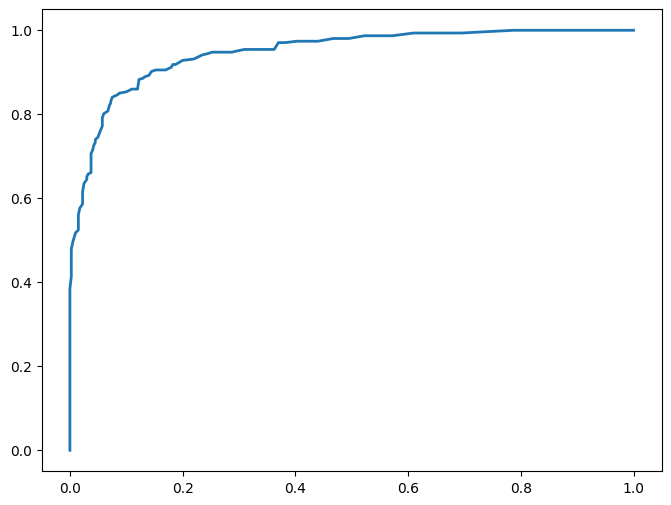

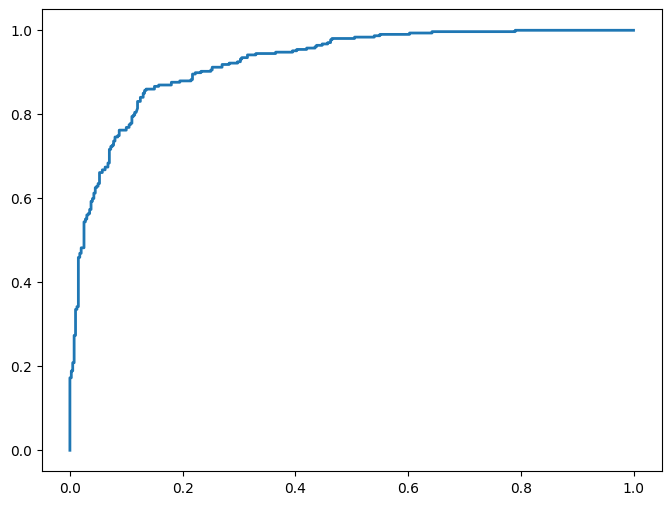

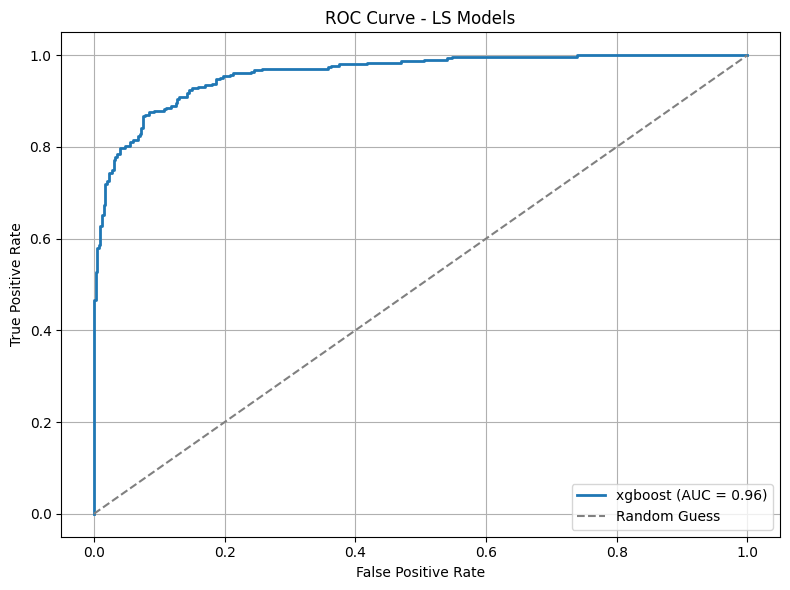

In [ ]:
# Define models
models = {
    'random_forest': RandomForestClassifier(random_state=42),
    'svm': SVC(probability=True, class_weight='balanced', random_state=42),
    'xgboost': XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

# Parameter spaces
param_spaces = {
    'random_forest': {
        'n_estimators': Integer(100, 300),
        'max_depth': Integer(5, 20),
        'min_samples_split': Integer(2, 10),
        'min_samples_leaf': Integer(1, 10),
        'criterion': Categorical(['gini', 'entropy']),
        'class_weight': Categorical(['balanced', 'balanced_subsample'])
    },
    'svm': {
        'C': Real(0.1, 10.0, prior='log-uniform'),
        'gamma': Real(1e-4, 1e-1, prior='log-uniform'),
        'kernel': Categorical(['rbf'])
    },
    'xgboost': {
        'n_estimators': Integer(100, 300),
        'max_depth': Integer(3, 10),
        'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
        'subsample': Real(0.6, 1.0),
        'colsample_bytree': Real(0.6, 1.0)
    }
}

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = {}
trained_models = {}

# Training loop
for name, model in models.items():
    print(f"\n🔎 Tuning {name.upper()}...")
    search = BayesSearchCV(
        estimator=model,
        search_spaces=param_spaces[name],
        n_iter=25,
        scoring='f1',
        cv=cv_strategy,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train_scaled, y_train)
    best_model = search.best_estimator_

    # # Calibrate probabilities
    # calibrated_model = CalibratedClassifierCV(best_model, cv=3)
    # calibrated_model.fit(X_train_scaled, y_train)
    # best_model = calibrated_model

    trained_models[name] = best_model
    y_pred = best_model.predict(X_test_scaled)
# ==================== ROC-AUC ====================
    plt.figure(figsize=(8, 6))
    y_score = best_model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc:.2f})")


    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    cr = classification_report(y_test, y_pred)

    print(f"✅ Best Params for {name}: {search.best_params_}")
    print(f"🎯 Accuracy on Test Set: {acc:.4f}")
    print("🧮 Confusion Matrix:\n", cm)
    print("📄 Classification Report:\n", cr)
    results[name] = {
        'model': best_model,
        'accuracy': acc,
        'confusion_matrix': cm,
        'classification_report': cr,
        'best_params': search.best_params_
        }




# Print final accuracy of all models
for name, model in trained_models.items():
    preds = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    print(f"✅ {name.upper()} Final Accuracy: {acc:.4f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - LS Models")
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{output_path}/roc_auc_curve.png")
plt.show()


In [ ]:
# ==================== SOFT VOTING ENSEMBLE ====================

probs = []

for name, model in trained_models.items():
    p = model.predict_proba(X_test_scaled)[:, 1]
    probs.append(p)

# Average probabilities
y_score_soft = np.mean(probs, axis=0)

# Binary prediction (0.5 threshold)
y_pred_soft = (y_score_soft >= 0.5).astype(int)

print("🔹 Soft Voting Accuracy:", accuracy_score(y_test, y_pred_soft))
print("🔹 Soft Voting ROC-AUC:", auc(*roc_curve(y_test, y_score_soft)[:2]))


🔹 Soft Voting Accuracy: 0.8896746817538896
🔹 Soft Voting ROC-AUC: 0.9589087947882736


In [ ]:
for name, model in models.items():
  for scale, raster in raster_sets.items():
    # Save raster prediction
    try:
        susceptibility = predict_raster(model, raster, ref_profile, scaler=scaler)
        profile = ref_profile.copy()
        profile.update(dtype=rasterio.float32, count=1, compress='lzw', nodata=np.nan)
        save_path = os.path.join(output_path, f"landslide_susceptibility_{name}_{scale}.tif")
        with rasterio.open(save_path, 'w', **profile) as dst:
            dst.write(susceptibility, 1)
        print(f"📂 Raster for {name} {scale} saved as: {save_path}")
    except Exception as e:
        print(f"{name} prediction failed:", e)



random_forest prediction failed: Attempt to create new tiff file '/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/outputs/landslide_susceptibility_random_forest_25x25.tif' failed: /content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/outputs/landslide_susceptibility_random_forest_25x25.tif: Operation not supported
random_forest prediction failed: Attempt to create new tiff file '/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/outputs/landslide_susceptibility_random_forest_15x15.tif' failed: /content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/outputs/landslide_susceptibility_random_forest_15x15.tif: Operation not supported


In [ ]:
features = []
names = []
for path in raster_files:
        names.append(path.replace("/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/",""))
        # names.append(raster_files)
        with rasterio.open(path) as src:
            band = src.read(1).astype(np.float32)
            band[band == src.nodata] = np.nan
            features.append(band)
for i, band in enumerate(features):
  print(f"Raster {names[i]}: shape = {band.shape}")